# 06 · Контрольные рейсы и временное выравнивание

**Исследовательский вопрос:** Насколько меняется сопоставление, если восстановить позицию точно ко времени C40?

**Входные материалы:** метаданные контрольных случаев и локальные последовательности EPWA/EGCC

Расчеты ниже выполняются в ячейках. Все исходные строки сохраняются. Округление таблиц используется только для чтения результатов.

In [1]:
# Подключаем библиотеки и находим корень проекта
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
# Подключаем проверенные геодезические функции без запуска скриптов
sys.path.insert(0, str(root/'europe/scripts'))
from audit_c40_radial_cases import ellipsoid_distance, validate_distance
from investigate_c40_geometry import distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})
# Таблицы округляем только при отображении, расчетные значения сохраняем
pd.set_option('display.max_columns', 14)


## 1. Проверяем состав контрольного пилота

Название этапа историческое: в таблице есть рейсы EPWA и EGCC. Сопоставление по ICAO24, времени и callsign не подтверждает тождество физических измерений разных источников.

In [2]:
controls = pd.read_csv(study/'reports/06_epwa_control_comparison.csv')
observed = pd.read_csv(study/'data/public_pilot/EPWA_control_geometry.csv')
display(controls[['flight_id','airport','status','expected_callsign','observed_callsign','callsign_matches','observed_rows']])
display(controls.groupby(['airport','status']).size().rename('Число случаев'))

,flight_id,airport,status,expected_callsign,observed_callsign,callsign_matches,observed_rows
0,EXS92K_22219,EGCC,matched_icao24_time,EXS92K,EXS92K,True,120
1,EZY89BW_37984,EGCC,matched_icao24_time,EZY89BW,EZY89BW,True,132
2,RYR72ZC_66456,EGCC,matched_icao24_time,RYR72ZC,RYR72ZC,True,130
3,EZY1942_18429,EGCC,matched_icao24_time,EZY1942,EZY1942,True,124
4,RYR67GT_63261,EGCC,matched_icao24_time,RYR67GT,RYR67GT,True,124
5,RYR4117_60025,EGCC,matched_icao24_time,RYR4117,RYR4117,True,123
6,EZY34MD_21230,EGCC,matched_icao24_time,EZY34MD,EZY34MD,True,119
7,ENT73JH_21100,EPWA,matched_icao24_time,ENT73JH,ENT73JH,True,121
8,EXS4112_71377,EGCC,matched_icao24_time,EXS4112,EXS4112,True,137
9,RYR9BN_63693,EGCC,matched_icao24_time,RYR9BN,RYR9BN,True,113


airport  status             
EGCC     matched_icao24_time    9
EPWA     matched_icao24_time    1
Name: Число случаев, dtype: int64

## 2. Пересчитываем позицию ко времени C40

Используем ближайшие доступные наблюдения до и после времени метаданных. При точном наблюдении интервал равен нулю. Если пары нет, результат остается отсутствующим.

In [3]:
# Восстанавливаем позицию только по концам временного интервала
rows = []
for case in controls.itertuples():
    track = observed[observed.case_flight_id.eq(case.flight_id)].sort_values('time')
    if track.empty:
        continue
    epoch = pd.Timestamp(case.c40_utc).timestamp()
    before, after = track[track.time <= epoch].tail(1), track[track.time >= epoch].head(1)
    if before.empty or after.empty:
        continue
    a,b = before.iloc[0],after.iloc[0]
    gap = b.time-a.time
    weight = 0 if gap == 0 else (epoch-a.time)/gap
    lat = a.lat+weight*(b.lat-a.lat)
    lon = a.lon+weight*(b.lon-a.lon)
    difference = float(1000*ellipsoid_distance(case.metadata_lat,case.metadata_lon,np.array([lat]),np.array([lon]))[0])
    rows.append({'flight_id':case.flight_id,'gap_s':gap,'recomputed_m':difference})
comparison = controls.merge(pd.DataFrame(rows),on='flight_id',how='left',validate='one_to_one')
valid = comparison.recomputed_m.notna()
assert np.allclose(comparison.loc[valid,'recomputed_m'],comparison.loc[valid,'interpolated_position_difference_m'])
display(comparison[['flight_id','airport','nearest_time_offset_s','gap_s','position_difference_m','recomputed_m']].round(2))

,flight_id,airport,nearest_time_offset_s,gap_s,position_difference_m,recomputed_m
0,EXS92K_22219,EGCC,-3.0,10,269.48,306.73
1,EZY89BW_37984,EGCC,0.0,0,491.31,491.31
2,RYR72ZC_66456,EGCC,-5.0,10,1359.27,508.29
3,EZY1942_18429,EGCC,-4.0,10,1132.33,348.01
4,RYR67GT_63261,EGCC,2.0,10,307.38,26.59
5,RYR4117_60025,EGCC,-5.0,10,659.14,185.28
6,EZY34MD_21230,EGCC,-4.0,10,949.89,206.71
7,ENT73JH_21100,EPWA,0.0,0,43035.86,43035.86
8,EXS4112_71377,EGCC,4.0,10,662.69,13.10
9,RYR9BN_63693,EGCC,-5.0,10,1143.23,137.12


## 3. Визуально сравниваем до и после выравнивания

Логарифмическая шкала нужна из-за большого разброса расстояний. Выравнивание времени не является исправлением метаданных; положительное или отрицательное изменение показано только описательно.

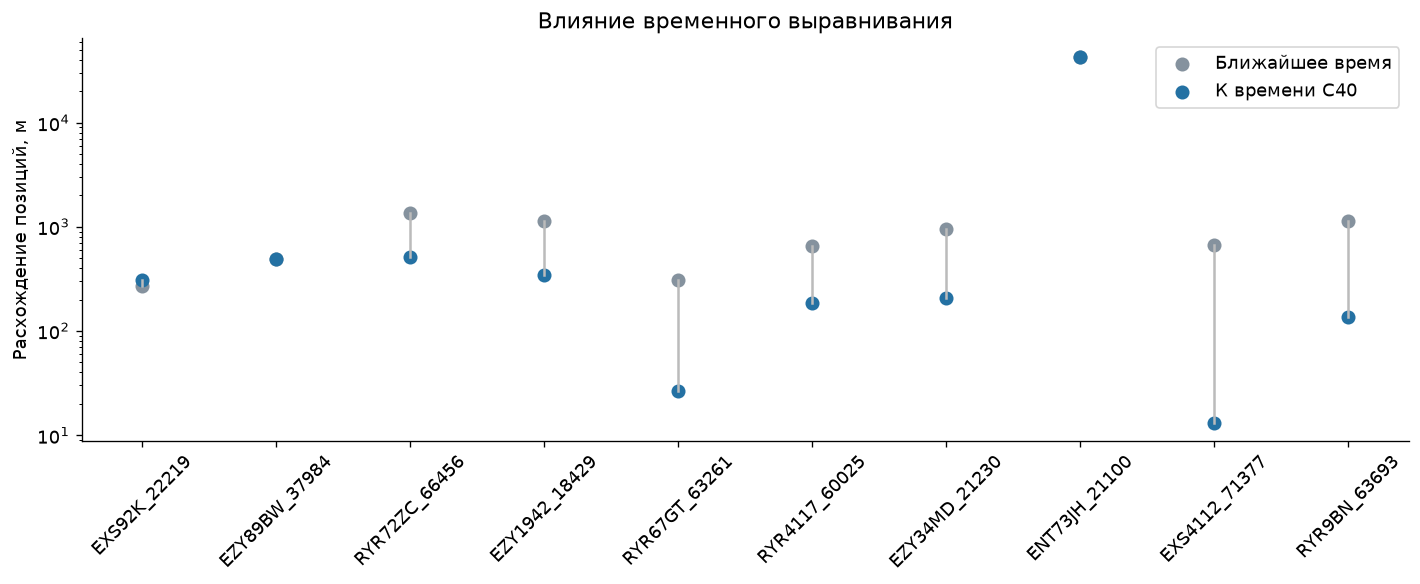

position_difference_m                     recomputed_m            \
                        count    median       max        count    median   
airport                                                                    
EGCC                        9    662.69   1359.27            9    206.71   
EPWA                        1  43035.86  43035.86            1  43035.86   

                   
              max  
airport            
EGCC       508.29  
EPWA     43035.86

In [4]:
# Ставим результаты методов рядом для каждого найденного случая
plot = comparison[comparison.recomputed_m.notna()].set_index('flight_id')
fig, ax = plt.subplots(figsize=(12,5))
x = np.arange(len(plot))
ax.scatter(x,plot.position_difference_m,label='Ближайшее время',color='#85929E',s=55)
ax.scatter(x,plot.recomputed_m,label='К времени C40',color='#2471A3',s=55)
for i,row in enumerate(plot.itertuples()):
    ax.plot([i,i],[row.position_difference_m,row.recomputed_m],color='#bbb')
ax.set(xticks=x,xticklabels=plot.index,yscale='log',ylabel='Расхождение позиций, м',title='Влияние временного выравнивания')
ax.tick_params(axis='x',rotation=45)
ax.legend()
plt.tight_layout()
plt.show()
# Не смешиваем итог по аэропортам и сохраняем число найденных случаев
display(plot.groupby('airport')[['position_difference_m','recomputed_m']].agg(['count','median','max']).round(2))

## Что установлено и что остается открытым

Временное выравнивание проверено прямым пересчетом, но не объясняет все расхождения. Контрольные рейсы одного пилота не позволяют сделать вывод обо всех датах и аэропортах. Следующий этап 07 скрывает известные точки, чтобы оценить точность восстановления на проверочных ответах.

## Методические подробности и происхождение источников

# Контрольное сопоставление четырех аэропортов

В EPWA в выбранном часе есть только исходный случай. Для контроля выбраны все сохраненные посадки EPWA, EGCC, EDDF и EGLL с C40 в 22-м часе UTC 21.10.2019, без отбора по величине отклонения. Использованы уже скачанные публичные часы 22 и 23 UTC. Это локальная контрольная группа, а не случайная выборка аэропортов.

Сопоставление: ICAO24, время и callsign; дополнительно показано положение около времени посадки. onground и барометрическая высота не используются сами по себе как подтверждение касания. Барометрическая высота приведена в метрах как в источнике, не AGL. Исторический ARP EPWA еще не подтвержден.

Временная привязка использует ближайший state vector; его сдвиг от времени C40 и возраст позиции показаны отдельно. Дополнительно координаты линейно интерполируются между соседними наблюдениями к точному времени C40. Это оценка, а не наблюденная позиция; интервал интерполяции приведен отдельно. На графике расстояний логарифмическая шкала.

Изменение центра не меняет геодезическое расстояние между координатами двух источников. Поэтому независимая проверка ARP важна для радиусов, но не объясняет само межисточниковое позиционное расхождение. В выбранном часе из четырех предусмотренных аэропортов записи есть только в EPWA и EGCC; нулевое число в других аэропортах не считается проверкой отсутствия посадок в исходной базе.

Ни координаты метаданных, ни OpenSky не объявляются истинными без дальнейшей проверки. Все исходные значения и строки сохраняются. Источник: https://opensky-network.org/datasets/ ; SHA256 двух архивов – в отчетах 05_public_pilot_download*.json.


---

Воспроизведение: `.\.venv\Scripts\python.exe -u -X utf8 research/c40_geometry/scripts/compare_public_epwa_controls.py`. Крупное расхождение – диагностическое наблюдение, не правило удаления. Следующая проверка: другая дата, исходное объединение полей, возможность систематической ошибки координат.